# 2 · Testing Linear Regression Models

**Testing a regression model:**
1. **Baseline.** A `DummyRegressor` that predicts the mean. Anything that doesn't beat it is useless.
2. **Metrics with cross-validation.** Report several, because each penalizes errors differently.
3. **Out-of-fold diagnostics.** Residual plots show *how* the model is wrong.
4. **Learning and validation curves.** Is the model under- or over-fitting, and is the regularization strength right?
5. **Statistical tests** (statsmodels). Are coefficients significant, and do the OLS assumptions hold?

Dataset: **Ames House Prices** (Kaggle *House Prices*): 1460 houses and 79 mixed-type features. The target is `SalePrice`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

plt.style.use("seaborn-v0_8-whitegrid")
plt.rc("figure", autolayout=True, figsize=(10, 4))

In [2]:
houses = fetch_openml(name="house_prices", as_frame=True).frame
X = houses.drop(columns=["Id", "SalePrice"])
y = houses["SalePrice"]
print(X.shape)
y.describe()

(1460, 79)


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

## 1. Pipeline: preprocessing + linear model on a log target
Prices are right-skewed. `TransformedTargetRegressor` fits on `log1p(y)` and converts predictions back automatically.

In [3]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, LassoCV
from sklearn.dummy import DummyRegressor

preprocess = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
     make_column_selector(dtype_include="number")),
    ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="None", keep_empty_features=True),
                          OneHotEncoder(handle_unknown="ignore", min_frequency=10)),
     make_column_selector(dtype_include=["object", "category"])),
])

def log_target(model):
    return TransformedTargetRegressor(make_pipeline(preprocess, model), func=np.log1p, inverse_func=np.expm1)

models = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "OLS": log_target(LinearRegression()),
    "Ridge": log_target(Ridge(alpha=10)),
    "Lasso": log_target(LassoCV(cv=5, alphas=30, max_iter=5000)),
}

## 2. Metrics with cross-validation

| Metric | Formula idea | Read it as | Note |
|---|---|---|---|
| **MAE** | mean \|y − ŷ\| | typical error in target units | robust to outliers |
| **RMSE** | √mean (y − ŷ)² | error in target units, big misses weigh more | the usual default |
| **R²** | 1 − SSE/SST | share of variance explained | 0 = no better than the mean; can go negative |
| **MAPE** | mean \|y − ŷ\|/\|y\| | relative error | unstable near y = 0 |
| **RMSLE** | RMSE of log1p | relative error, under-predictions hurt more | the Kaggle House Prices metric |

`cross_validate` reports several metrics at once. Scikit-learn uses the convention that *greater is better*, so error scores come back negated.

In [4]:
from sklearn.model_selection import KFold, cross_validate

cv = KFold(n_splits=5, shuffle=True, random_state=0)      # same folds for every model → fair comparison
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
    "MAPE": "neg_mean_absolute_percentage_error",
    "RMSLE": "neg_root_mean_squared_log_error",
}

cv_results = {name: cross_validate(m, X, y, cv=cv, scoring=scoring) for name, m in models.items()}

summary = pd.DataFrame({
    name: {metric: res[f"test_{metric}"].mean() * (1 if metric == "R2" else -1) for metric in scoring}
    for name, res in cv_results.items()
}).T
summary.style.format("{:.3f}", subset=["R2", "MAPE", "RMSLE"]).format("{:,.0f}", subset=["MAE", "RMSE"])

,MAE,RMSE,R2,MAPE,RMSLE
Baseline (mean),"57,572","79,385",-0.013,0.364,0.408
OLS,"17,277","40,902",0.672,0.101,0.148
Ridge,"16,970","44,765",0.532,0.100,0.144
Lasso,"16,905","46,291",0.469,0.100,0.144


**Metrics can disagree.** Ridge and Lasso win on RMSLE and MAE but lose on RMSE and R². A handful of very large houses
produce huge errors in dollars, and squared-error metrics are dominated by them. The log target optimizes *relative* error,
so it pays least attention to exactly those houses. Choose the model by the metric you'll be judged on.

**Look at the spread across folds, not just the mean.** Two models whose fold scores overlap heavily aren't meaningfully different.

,OLS,Ridge,Lasso
mean,0.1479,0.1439,0.1440
std,0.0318,0.0357,0.0373


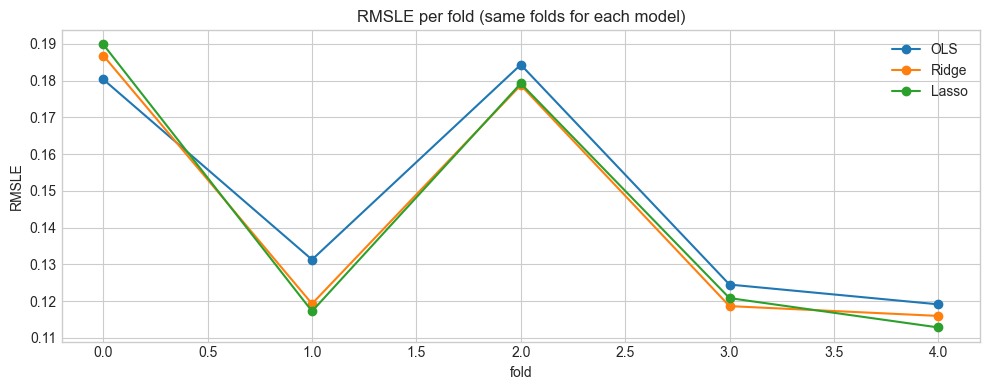

In [5]:
fold_rmsle = pd.DataFrame({name: -res["test_RMSLE"] for name, res in cv_results.items() if name != "Baseline (mean)"})
ax = fold_rmsle.plot(marker="o", title="RMSLE per fold (same folds for each model)", xlabel="fold", ylabel="RMSLE")
fold_rmsle.agg(["mean", "std"]).round(4)

In [6]:
from scipy import stats

# Paired comparison on the same folds. Fold scores aren't independent, so treat the p-value as a rough guide.
t, p = stats.ttest_rel(fold_rmsle["Ridge"], fold_rmsle["Lasso"])
print(f"Ridge vs Lasso: mean diff {(fold_rmsle['Ridge'] - fold_rmsle['Lasso']).mean():+.4f}, paired t-test p = {p:.3f}")

Ridge vs Lasso: mean diff -0.0001, paired t-test p = 0.938


## 3. Diagnostics from out-of-fold predictions
`cross_val_predict` gives a prediction for every row, each from a model that **didn't see that row**. Plot those, not training-set fits.

| Plot | Healthy | Problem it reveals |
|---|---|---|
| actual vs predicted | points on the diagonal | systematic bias at low or high values |
| residual vs predicted | flat band around 0 | curvature (missing non-linearity), funnel shape (heteroskedasticity) |
| residual histogram / Q-Q | symmetric, close to the line | heavy tails, outliers |

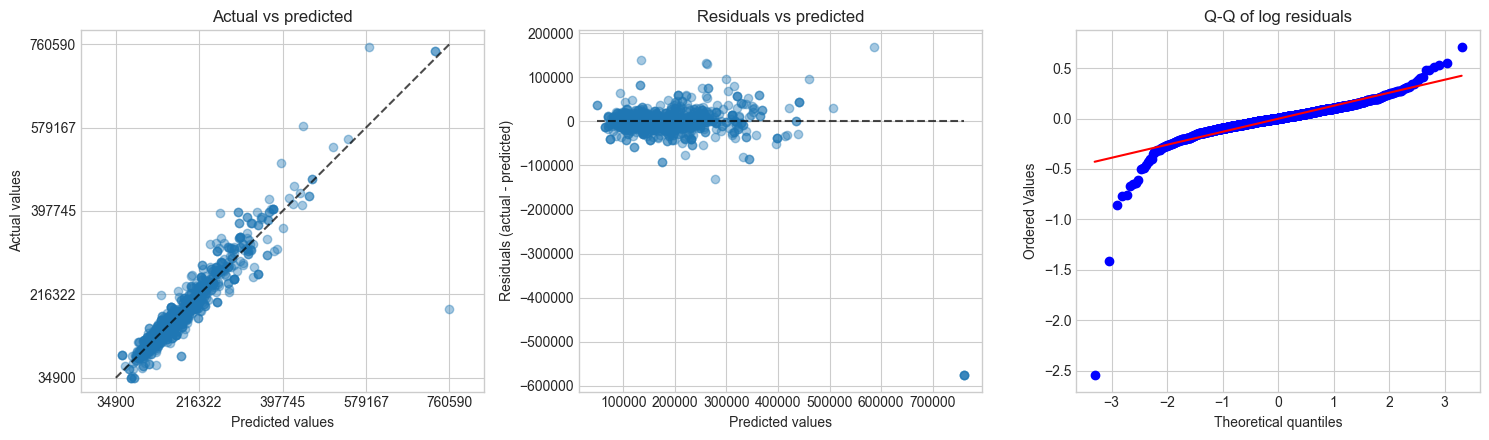

In [7]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import PredictionErrorDisplay

y_oof = cross_val_predict(models["Ridge"], X, y, cv=cv)

fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
PredictionErrorDisplay.from_predictions(y, y_oof, kind="actual_vs_predicted", ax=axs[0], scatter_kwargs={"alpha": 0.4})
PredictionErrorDisplay.from_predictions(y, y_oof, kind="residual_vs_predicted", ax=axs[1], scatter_kwargs={"alpha": 0.4})
stats.probplot(np.log1p(y) - np.log1p(y_oof), plot=axs[2])
axs[0].set_title("Actual vs predicted"); axs[1].set_title("Residuals vs predicted"); axs[2].set_title("Q-Q of log residuals");

In [8]:
# The biggest misses are worth inspecting; they're often data errors or special cases
worst = (np.log1p(y) - np.log1p(y_oof)).abs().sort_values(ascending=False).head(5).index
houses.loc[worst, ["SalePrice", "GrLivArea", "OverallQual", "SaleCondition"]].assign(predicted=y_oof[worst].round(-3))

,SalePrice,GrLivArea,OverallQual,SaleCondition,predicted
1298,160000,5642,10,Partial,2038000.0
523,184750,4676,10,Partial,761000.0
30,40000,1317,4,Normal,94000.0
495,34900,720,4,Abnorml,75000.0
632,82500,1411,7,Family,176000.0


## 4. Learning and validation curves
- **Learning curve** (score vs. training size). If the train and validation curves are both poor and close together, the model is underfitting (high bias), so add features or complexity.
  A large, persistent gap means overfitting (high variance), so regularize or get more data.
- **Validation curve** (score vs. one hyperparameter). Choose the value where the validation score peaks.

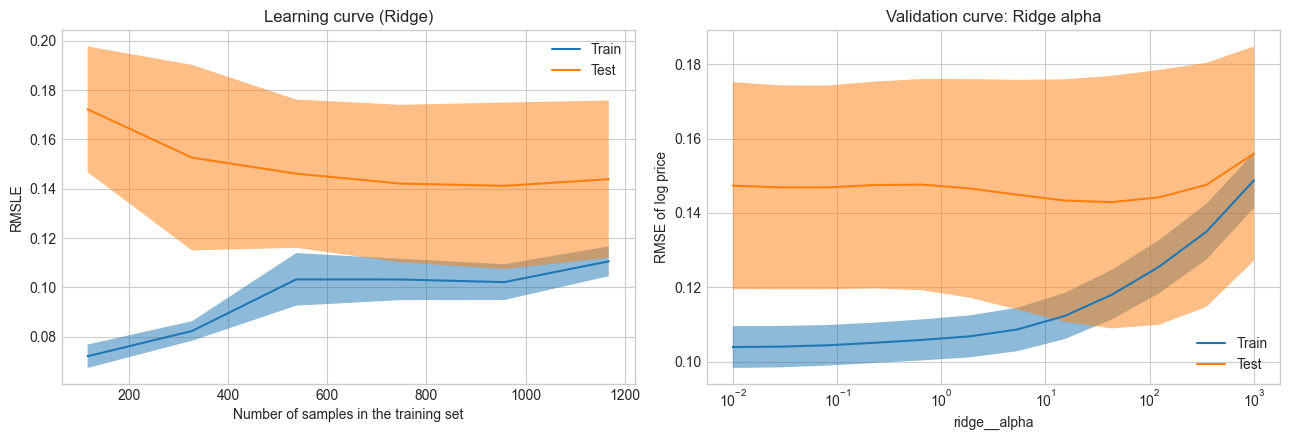

In [9]:
from sklearn.model_selection import LearningCurveDisplay, ValidationCurveDisplay

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
LearningCurveDisplay.from_estimator(
    models["Ridge"], X, y, cv=cv, scoring="neg_root_mean_squared_log_error",
    train_sizes=np.linspace(0.1, 1.0, 6), negate_score=True, ax=ax1,
)
ax1.set(title="Learning curve (Ridge)", ylabel="RMSLE")

ridge_pipe = make_pipeline(preprocess, Ridge())
ValidationCurveDisplay.from_estimator(
    ridge_pipe, X, np.log1p(y), param_name="ridge__alpha", param_range=np.logspace(-2, 3, 12),
    cv=cv, scoring="neg_root_mean_squared_error", negate_score=True, ax=ax2,
)
ax2.set(xscale="log", title="Validation curve: Ridge alpha", ylabel="RMSE of log price");

## 5. Statistical tests on an OLS model (statsmodels)
Scikit-learn is built for prediction. For **inference** (are the coefficients real, and do the assumptions hold?) use `statsmodels`.
The example uses a small model with a few interpretable features.

In [10]:
import statsmodels.api as sm

features = ["OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF", "YearBuilt", "FullBath"]
data = houses[features + ["SalePrice"]].dropna()
X_sm = sm.add_constant(data[features])
y_sm = np.log(data["SalePrice"])

ols = sm.OLS(y_sm, X_sm).fit()
ols.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              SalePrice   R-squared:                       0.812
Model:                            OLS   Adj. R-squared:                  0.811
Method:                 Least Squares   F-statistic:                     1046.
Date:                Thu, 19 Nov 2026   Prob (F-statistic):               0.00
Time:                        22:40:26   Log-Likelihood:                 488.47
No. Observations:                1460   AIC:                            -962.9
Df Residuals:                    1453   BIC:                            -925.9
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           6.0057      0.410     14.643      0.000       5.201       6.810
OverallQual     0.1031      0.005     19.653      0.000       0.093       0.113
GrLivArea       0.0002   1.36e-05     17.971      0.000       0.000       0.000
GarageCars      0.0879      0.008     10.643      0.000       0.072       0.104
TotalBsmtSF     0.0001   1.29e-05      9.505      0.000    9.72e-05       0.000
YearBuilt       0.0024      0.000     11.147      0.000       0.002       0.003
FullBath       -0.0075      0.012     -0.624      0.533      -0.031       0.016
==============================================================================
Omnibus:                      928.162   Durbin-Watson:                   1.992
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            32710.582
Skew:                          -2.409   Prob(JB):                         0.00
Kurtosis:                      25.682   Cond. No.                     2.47e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.47e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

**Reading the summary:**
- `coef`: the effect on log-price of a one-unit increase, holding the others fixed. `100·coef` is roughly the % change.
- `P>|t|`: the t-test of H₀: coef = 0. `[0.025 0.975]` is the 95% confidence interval.
- `F-statistic`: the test that *all* the slopes are zero. `Adj. R-squared` penalizes extra features.
- `Durbin-Watson` near 2 means no autocorrelation in the residuals. `Jarque-Bera` tests the residuals for normality. A large `Cond. No.` warns of multicollinearity.

In [11]:
# Joint hypothesis: are both bathroom and basement features zero?
print(ols.f_test("FullBath = 0, TotalBsmtSF = 0"))

<F test: F=47.02585956498612, p=1.6244554339980933e-20, df_denom=1.45e+03, df_num=2>


In [12]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Heteroskedasticity: H0 = residual variance is constant
_, bp_pvalue, _, _ = het_breuschpagan(ols.resid, X_sm)
print(f"Breusch-Pagan p = {bp_pvalue:.2g}  → if small, use robust SEs: sm.OLS(...).fit(cov_type='HC3')")

# Multicollinearity: VIF > ~5-10 means the coefficient is poorly identified
pd.Series([variance_inflation_factor(X_sm.values, i) for i in range(1, X_sm.shape[1])],
          index=features, name="VIF").round(2)

Breusch-Pagan p = 3.5e-49  → if small, use robust SEs: sm.OLS(...).fit(cov_type='HC3')


OverallQual    2.55
GrLivArea      2.47
GarageCars     1.85
TotalBsmtSF    1.55
YearBuilt      2.06
FullBath       2.12
Name: VIF, dtype: float64

In [13]:
ols_robust = sm.OLS(y_sm, X_sm).fit(cov_type="HC3")      # same coefficients, heteroskedasticity-robust SEs
pd.DataFrame({"coef": ols.params, "SE": ols.bse, "robust SE": ols_robust.bse, "robust p": ols_robust.pvalues}).round(4)

,coef,SE,robust SE,robust p
const,6.0057,0.4101,0.5926,0.0000
OverallQual,0.1031,0.0052,0.0091,0.0000
GrLivArea,0.0002,0.0000,0.0000,0.0000
GarageCars,0.0879,0.0083,0.0169,0.0000
TotalBsmtSF,0.0001,0.0000,0.0001,0.0198
YearBuilt,0.0024,0.0002,0.0003,0.0000
FullBath,-0.0075,0.0120,0.0235,0.7497


**Takeaways**
- Always compare against a `DummyRegressor`, and use the **same CV folds** for every model.
- Report several metrics. Choose the one that matches the competition or business cost (RMSLE for Kaggle House Prices).
- Diagnose with **out-of-fold** predictions. Residual patterns tell you what to fix next.
- Use learning and validation curves for bias/variance and regularization. Use statsmodels for coefficient tests and assumption checks.